# File integrity manifests

Check a directory snapshot against a previously recorded SHA-256 manifest.

Hash files in chunks and compare by relative name. Distinguish content changes from additions and removals. The expected manifest must come from a trusted source.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hashlib import sha256
from pathlib import Path
from tempfile import TemporaryDirectory
from collections import Counter

## Run the local experiment

All records used below belong to the small fixture supplied by the example.

{'guide': 'changed', 'index': 'same', 'notes': 'missing', 'table': 'added'}


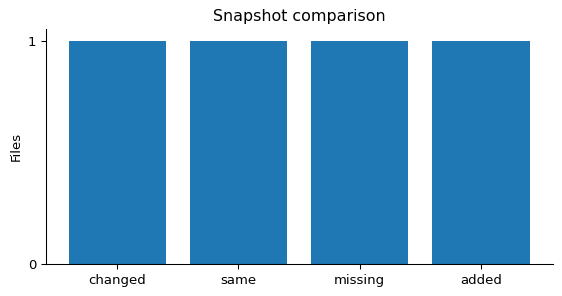

In [2]:
def snapshot(root):
    hashes = {}
    for path in sorted(root.iterdir()):
        if path.is_file():
            h = sha256()
            with path.open("rb") as stream:
                for chunk in iter(lambda: stream.read(8192), b""):
                    h.update(chunk)
            hashes[path.name] = h.hexdigest()
    return hashes


with TemporaryDirectory() as work:
    root = Path(work)
    for name, data in {"guide": "edition one", "index": "entry A", "notes": "note"}.items():
        (root / name).write_text(data)
    first = snapshot(root)
    (root / "guide").write_text("edition two")
    (root / "notes").unlink()
    (root / "table").write_text("1,2")
    last = snapshot(root)
states = {
    k: (
        "added"
        if k not in first
        else "missing" if k not in last else "same" if first[k] == last[k] else "changed"
    )
    for k in sorted(first.keys() | last.keys())
}
print(states)
counts = Counter(states.values())
assert set(counts) == {"added", "missing", "same", "changed"}
fig, ax = plt.subplots(figsize=(5.8, 3), constrained_layout=True)
ax.bar(counts.keys(), counts.values())
ax.set(ylabel="Files", yticks=[0, 1], title="Snapshot comparison")
plt.show()

## Interpreting the result

A digest mismatch identifies changed bytes. It cannot explain when or why the file changed.

## Exercise

Hash the same directory after renaming a file and trace the manifest difference.

## References

[Python, hashlib](https://docs.python.org/3/library/hashlib.html)

[NIST Cybersecurity Framework 2.0](https://doi.org/10.6028/NIST.CSWP.29)